<a href="https://colab.research.google.com/github/fathimaajvad/NLP-Assignment/blob/main/Context_Aware_Sarcasm_Implicit_Sentiment_Detection_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Context-Aware Sarcasm and Implicit Sentiment Detection Using NLP

This notebook treats two tasks separately:

1. **Sarcasm detection** on the News Headlines Dataset for Sarcasm Detection (Misra, 2019). Models: TF-IDF + Logistic Regression baseline and a fine-tuned DistilBERT.
2. **Sentiment classification** on the IMDb movie-review dataset (Maas et al., 2011). This is a different task and domain.

Sentiment output is a model prediction. It is **not** verified intended sentiment, and the sarcasm dataset has no intended-sentiment labels, so intended sentiment is not evaluated here.

Run top to bottom on a **T4 GPU** (Runtime → Change runtime type → T4 GPU). Expected runtime is about 10–20 minutes.

## 1. Setup

In [1]:
!pip -q install -U ipywidgets

import os, time, random, urllib.request, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import sklearn, transformers, datasets
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, ConfusionMatrixDisplay)
from IPython.display import display

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"
RES, FIG = "results", "figures"
os.makedirs(RES, exist_ok=True); os.makedirs(FIG, exist_ok=True)

print("torch", torch.__version__, "| transformers", transformers.__version__,
      "| datasets", datasets.__version__, "| sklearn", sklearn.__version__)
print("Device:", DEVICE, torch.cuda.get_device_name(0) if USE_AMP else "")

def metrics_row(name, y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="binary", zero_division=0)
    return {"model": name, "accuracy": accuracy_score(y_true, y_pred),
            "precision": p, "recall": r, "f1": f}

def save_confusion(y_true, y_pred, title, path):
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred),
                           display_labels=["Not sarcastic", "Sarcastic"]).plot(ax=ax, colorbar=False)
    ax.set_title(title)
    fig.tight_layout(); fig.savefig(path, dpi=150); plt.show()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.1/140.1 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 17.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 42.7 MB/s eta 0:00:00
torch 2.11.0+cu130 | transformers 5.20.1 | datasets 4.8.5 | sklearn 1.6.1
Device: cuda Tesla T4


## 2. Load the sarcasm dataset
Downloads the published JSON-lines file from the dataset's GitHub repository. If the download fails, upload `Sarcasm_Headlines_Dataset.json` with the Colab folder icon and rerun this cell.

In [2]:
SARC_URL = "https://raw.githubusercontent.com/rishabhmisra/News-Headlines-Dataset-For-Sarcasm-Detection/master/Sarcasm_Headlines_Dataset.json"
SARC_FILE = "Sarcasm_Headlines_Dataset.json"
if not os.path.exists(SARC_FILE):
    try:
        urllib.request.urlretrieve(SARC_URL, SARC_FILE)
    except Exception as e:
        raise RuntimeError(f"Download failed ({e}). Upload {SARC_FILE} with the folder icon and rerun.") from e

raw = pd.read_json(SARC_FILE, lines=True)
print("Raw shape:", raw.shape, "| columns:", list(raw.columns))
print("Missing values per column:", raw.isna().sum().to_dict())

sarc = raw[["headline", "is_sarcastic"]].rename(columns={"headline": "text", "is_sarcastic": "label"})
sarc = sarc.dropna()
sarc["text"] = sarc["text"].astype(str).str.strip()
sarc = sarc[sarc["text"].str.len() > 0].copy()
sarc["label"] = sarc["label"].astype(int)
n_dup = int(sarc.duplicated("text").sum())
sarc = sarc.drop_duplicates("text").reset_index(drop=True)
print(f"Duplicate headlines removed: {n_dup} | rows after cleaning: {len(sarc):,}")
print("Label counts (0 = not sarcastic, 1 = sarcastic):", sarc["label"].value_counts().to_dict())
display(sarc.head(3))

Raw shape: (28619, 3) | columns: ['is_sarcastic', 'headline', 'article_link']
Missing values per column: {'is_sarcastic': 0, 'headline': 0, 'article_link': 0}
Duplicate headlines removed: 116 | rows after cleaning: 28,503
Label counts (0 = not sarcastic, 1 = sarcastic): {0: 14951, 1: 13552}


,text,label
0,thirtysomething scientists unveil doomsday clo...,1
1,dem rep. totally nails why congress is falling...,0
2,eat your veggies: 9 deliciously different recipes,0


## 3. Exploratory data analysis

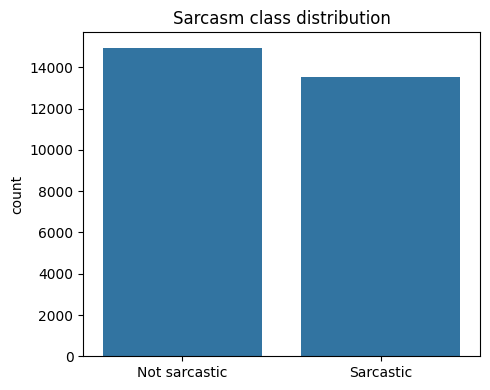

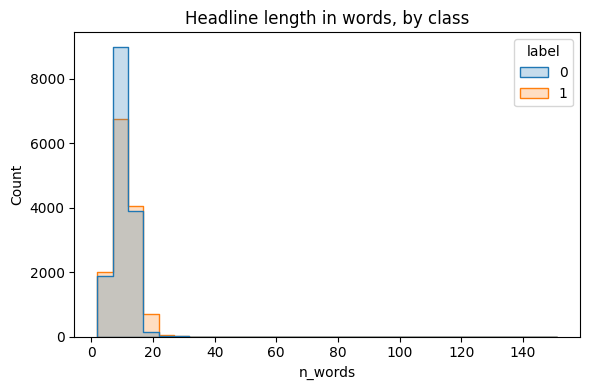

{'count': 28503.0, 'mean': 10.06, 'std': 3.39, 'min': 2.0, '25%': 8.0, '50%': 10.0, '75%': 12.0, 'max': 151.0}
Sarcastic examples:


,text
0,thirtysomething scientists unveil doomsday clo...
3,inclement weather prevents liar from getting t...
4,mother comes pretty close to using word 'strea...


Not sarcastic examples:


,text
1,dem rep. totally nails why congress is falling...
2,eat your veggies: 9 deliciously different recipes
5,my white inheritance


In [3]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=sarc, x="label", ax=ax)
ax.set_xticks([0, 1]); ax.set_xticklabels(["Not sarcastic", "Sarcastic"])
ax.set_xlabel(""); ax.set_title("Sarcasm class distribution")
fig.tight_layout(); fig.savefig(f"{FIG}/class_distribution.png", dpi=150); plt.show()

sarc["n_words"] = sarc["text"].str.split().str.len()
fig, ax = plt.subplots(figsize=(6, 4))
sns.histplot(data=sarc, x="n_words", hue="label", bins=30, element="step", ax=ax)
ax.set_title("Headline length in words, by class")
fig.tight_layout(); fig.savefig(f"{FIG}/text_length.png", dpi=150); plt.show()
print(sarc["n_words"].describe().round(2).to_dict())

print("Sarcastic examples:"); display(sarc.loc[sarc["label"] == 1, "text"].head(3))
print("Not sarcastic examples:"); display(sarc.loc[sarc["label"] == 0, "text"].head(3))

## 4. Stratified train / validation / test split
Duplicates were removed before splitting. The test set is used only for final evaluation.

In [4]:
train_df, test_df = train_test_split(sarc, test_size=0.15, stratify=sarc["label"], random_state=SEED)
train_df, val_df = train_test_split(train_df, test_size=0.1765, stratify=train_df["label"], random_state=SEED)
print(f"Train: {len(train_df):,} | Validation: {len(val_df):,} | Test: {len(test_df):,}")

Train: 19,950 | Validation: 4,277 | Test: 4,276


## 5. Baseline: TF-IDF + Logistic Regression (sarcasm)
The regularisation strength C is selected on the validation set only.

Validation F1 by C: {0.5: 0.839, 1.0: 0.847, 4.0: 0.8583} -> selected C = 4.0
{'model': 'TF-IDF + Logistic Regression', 'accuracy': 0.8479887745556595, 'precision': 0.8241912798874824, 'recall': 0.8647319232661091, 'f1': 0.843975036005761}


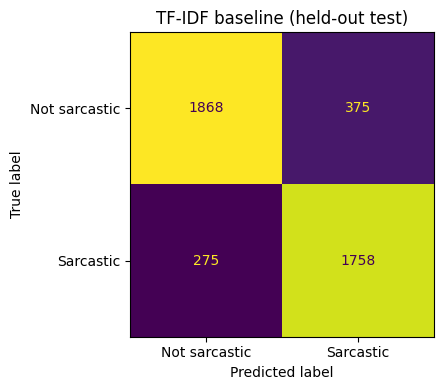

In [5]:
def make_baseline(C):
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("clf", LogisticRegression(C=C, max_iter=2000, class_weight="balanced", random_state=SEED)),
    ])

val_f1 = {}
for C in [0.5, 1.0, 4.0]:
    m = make_baseline(C).fit(train_df["text"], train_df["label"])
    val_f1[C] = metrics_row("val", val_df["label"], m.predict(val_df["text"]))["f1"]
best_C = max(val_f1, key=val_f1.get)
print("Validation F1 by C:", {k: round(v, 4) for k, v in val_f1.items()}, "-> selected C =", best_C)

baseline = make_baseline(best_C).fit(train_df["text"], train_df["label"])
base_pred = baseline.predict(test_df["text"])
base_row = metrics_row("TF-IDF + Logistic Regression", test_df["label"], base_pred)
print(base_row)
save_confusion(test_df["label"], base_pred, "TF-IDF baseline (held-out test)", f"{FIG}/baseline_confusion.png")

## 6. Contextual model: DistilBERT fine-tuning (sarcasm)
A plain PyTorch loop is used instead of the high-level Trainer, so the code does not depend on Trainer argument names that change between library versions. The best epoch is chosen on validation F1; the test set is evaluated once.

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'epoch': 1, 'train_loss': 0.2860845999362377, 'val_accuracy': 0.9097498246434417, 'val_f1': 0.9011776753712237, 'seconds': 41.1}
{'epoch': 2, 'train_loss': 0.13396202045707747, 'val_accuracy': 0.9233107318213701, 'val_f1': 0.9167089893346877, 'seconds': 41.2}
{'model': 'DistilBERT (fine-tuned, 2 epochs)', 'accuracy': 0.9242282507015903, 'precision': 0.9402369912416281, 'recall': 0.897688145597639, 'f1': 0.9184700553598389}


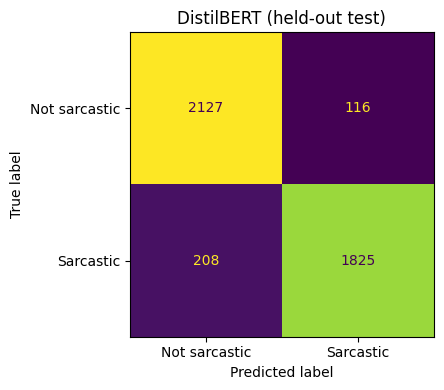

In [6]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.utils.data import DataLoader, TensorDataset
from torch.optim import AdamW

MODEL_NAME = "distilbert-base-uncased"
MAXLEN, BATCH, EPOCHS, LR = 64, 32, 2, 2e-5
tok = AutoTokenizer.from_pretrained(MODEL_NAME)

def to_loader(df, shuffle=False, batch=BATCH):
    enc = tok(list(df["text"]), truncation=True, max_length=MAXLEN,
              padding="max_length", return_tensors="pt")
    ds = TensorDataset(enc["input_ids"], enc["attention_mask"],
                       torch.tensor(df["label"].values, dtype=torch.long))
    gen = torch.Generator().manual_seed(SEED) if shuffle else None
    return DataLoader(ds, batch_size=batch, shuffle=shuffle, generator=gen)

model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(DEVICE)
opt = AdamW(model.parameters(), lr=LR, weight_decay=0.01)
scaler = torch.amp.GradScaler(DEVICE, enabled=USE_AMP)
train_dl = to_loader(train_df, shuffle=True)
val_dl = to_loader(val_df, batch=128)
test_dl = to_loader(test_df, batch=128)

@torch.no_grad()
def positive_probs(loader):
    model.eval(); out = []
    for ids, mask, _ in loader:
        with torch.autocast("cuda", enabled=USE_AMP):
            logits = model(input_ids=ids.to(DEVICE), attention_mask=mask.to(DEVICE)).logits
        out.append(torch.softmax(logits.float(), dim=-1)[:, 1].cpu())
    return torch.cat(out).numpy()

history, best_f1, best_state = [], -1.0, None
for epoch in range(1, EPOCHS + 1):
    model.train(); t0 = time.time(); losses = []
    for ids, mask, y in train_dl:
        opt.zero_grad()
        with torch.autocast("cuda", enabled=USE_AMP):
            loss = model(input_ids=ids.to(DEVICE), attention_mask=mask.to(DEVICE),
                         labels=y.to(DEVICE)).loss
        scaler.scale(loss).backward()
        scaler.step(opt); scaler.update()
        losses.append(loss.item())
    val_pred = (positive_probs(val_dl) >= 0.5).astype(int)
    vm = metrics_row("val", val_df["label"].values, val_pred)
    history.append({"epoch": epoch, "train_loss": float(np.mean(losses)),
                    "val_accuracy": vm["accuracy"], "val_f1": vm["f1"],
                    "seconds": round(time.time() - t0, 1)})
    print(history[-1])
    if vm["f1"] > best_f1:
        best_f1 = vm["f1"]
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}

model.load_state_dict(best_state)
bert_pred = (positive_probs(test_dl) >= 0.5).astype(int)
bert_row = metrics_row("DistilBERT (fine-tuned, 2 epochs)", test_df["label"].values, bert_pred)
print(bert_row)
save_confusion(test_df["label"].values, bert_pred, "DistilBERT (held-out test)", f"{FIG}/distilbert_confusion.png")

## 7. Separate sentiment classifier (IMDb)
TF-IDF + Logistic Regression trained on movie-review sentiment labels. Stop words are **not** removed, because words like 'not' carry negation. C is fixed and not tuned.

In [7]:
from datasets import load_dataset

imdb = load_dataset("stanfordnlp/imdb")
imdb_tr = imdb["train"].shuffle(seed=SEED).select(range(12000))
imdb_te = imdb["test"].shuffle(seed=SEED).select(range(3000))

sent_model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
    ("clf", LogisticRegression(C=2.0, max_iter=2000, random_state=SEED)),
])
sent_model.fit(imdb_tr["text"], imdb_tr["label"])
sent_pred = sent_model.predict(imdb_te["text"])
sent_row = metrics_row("IMDb TF-IDF + LR (sentiment)", np.array(imdb_te["label"]), sent_pred)
print("IMDb subset sizes: train", len(imdb_tr), "| test", len(imdb_te))
print(sent_row)

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

IMDb subset sizes: train 12000 | test 3000
{'model': 'IMDb TF-IDF + LR (sentiment)', 'accuracy': 0.8883333333333333, 'precision': 0.8811096433289299, 'recall': 0.8959032907991941, 'f1': 0.8884448884448884}


## 8. Model comparison and error analysis
The sarcasm comparison and the sentiment result are reported in separate tables because they measure different tasks.

,model,accuracy,precision,recall,f1
0,TF-IDF + Logistic Regression,0.8480,0.8242,0.8647,0.8440
1,"DistilBERT (fine-tuned, 2 epochs)",0.9242,0.9402,0.8977,0.9185


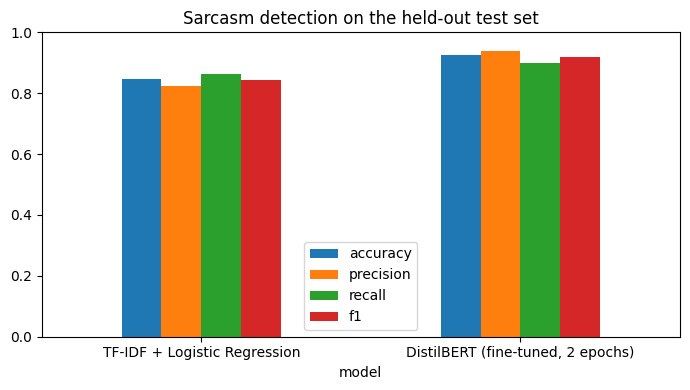

DistilBERT on test: false positives 116 | false negatives 208 | test size 4276
False positives (predicted sarcastic, actually not):


,text,label,pred
3,distributor will not release new louis c.k. fi...,0,1
49,capital in 21st century,0,1
87,supreme court to consider lifting class-action...,0,1
90,"white roof, low energy",0,1
107,surge soda again sells out on amazon,0,1
140,esa lander prepares for historic mars landing,0,1
165,men's mental health demands male friendship,0,1
166,judge agrees to hear resentencing motion in ga...,0,1


False negatives (missed sarcasm):


,text,label,pred
11,taylor swift inspires 200 million fans to regi...,1,0
40,samuel adams apologizes for 'boston sucks' pil...,1,0
50,12 shirtless firemen save woman from year of l...,1,0
51,300 million without electricity in india after...,1,0
74,4-year-old reportedly loved trip to italy,1,0
101,wildfires force colorado to airlift rocky moun...,1,0
141,bush caught in one of his own terror traps,1,0
146,"guillermo del toro: 'in today's society, the t...",1,0


In [8]:
comparison = pd.DataFrame([base_row, bert_row])
display(comparison.round(4))
comparison.to_csv(f"{RES}/sarcasm_model_comparison.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4))
comparison.set_index("model")[["accuracy", "precision", "recall", "f1"]].plot.bar(ax=ax, rot=0)
ax.set_title("Sarcasm detection on the held-out test set"); ax.set_ylim(0, 1)
fig.tight_layout(); fig.savefig(f"{FIG}/model_comparison.png", dpi=150); plt.show()

err = test_df[["text", "label"]].reset_index(drop=True).assign(pred=bert_pred)
fp = err[(err["label"] == 0) & (err["pred"] == 1)]
fn = err[(err["label"] == 1) & (err["pred"] == 0)]
print(f"DistilBERT on test: false positives {len(fp)} | false negatives {len(fn)} | test size {len(err)}")
print("False positives (predicted sarcastic, actually not):"); display(fp.head(8))
print("False negatives (missed sarcasm):"); display(fn.head(8))
err[err["label"] != err["pred"]].to_csv(f"{RES}/distilbert_errors.csv", index=False)

## 9. Prediction function and interactive demo
Sarcasm probability comes from the fine-tuned DistilBERT. Sentiment probability comes from the separate IMDb model. Neither probability is calibrated.

In [9]:
@torch.no_grad()
def sarcasm_prob(text):
    model.eval()
    enc = tok([text], truncation=True, max_length=MAXLEN, padding="max_length", return_tensors="pt")
    logits = model(input_ids=enc["input_ids"].to(DEVICE), attention_mask=enc["attention_mask"].to(DEVICE)).logits
    return torch.softmax(logits.float(), dim=-1)[0, 1].item()

NOTE = ("Probabilities are model outputs, not calibrated confidence. Sarcasm is context-dependent. "
        "Sentiment here is the polarity a model predicts from text, not verified intended sentiment.")

def predict(text):
    if not isinstance(text, str) or not text.strip():
        raise ValueError("Please enter a non-empty sentence.")
    p_sarc = sarcasm_prob(text)
    p_sent = sent_model.predict_proba([text])[0]   # classes order: [negative, positive]
    s = int(np.argmax(p_sent))
    return {
        "input": text,
        "sarcasm_label": "sarcastic" if p_sarc >= 0.5 else "not sarcastic",
        "sarcasm_probability": round(p_sarc, 3),
        "sentiment_label": ["negative", "positive"][s],
        "sentiment_probability": round(float(p_sent[s]), 3),
        "note": NOTE,
    }

examples = [
    "The movie was absolutely brilliant and moving.",          # clearly positive
    "This was the worst meal I have ever eaten.",              # clearly negative
    "Wow, what a wonderful service! I waited three hours.",    # sarcastic
    "The package arrived on Tuesday.",                         # neutral
    "I guess the meeting went fine, whatever that means.",     # ambiguous
]
demo = pd.DataFrame([predict(t) for t in examples])
display(demo[["input", "sarcasm_label", "sarcasm_probability", "sentiment_label", "sentiment_probability"]])
print("These hand-picked examples illustrate behaviour. They are not a substitute for the held-out test metrics.")

,input,sarcasm_label,sarcasm_probability,sentiment_label,sentiment_probability
0,The movie was absolutely brilliant and moving.,not sarcastic,0.003,positive,0.722
1,This was the worst meal I have ever eaten.,not sarcastic,0.003,negative,0.986
2,"Wow, what a wonderful service! I waited three ...",not sarcastic,0.005,positive,0.689
3,The package arrived on Tuesday.,not sarcastic,0.019,positive,0.517
4,"I guess the meeting went fine, whatever that m...",not sarcastic,0.003,negative,0.505


These hand-picked examples illustrate behaviour. They are not a substitute for the held-out test metrics.


### Retraining with Conversational Sarcasm Examples
We will now append specific conversational, context-dependent sarcastic examples (and some non-sarcastic counter-examples) to our training data and fine-tune our DistilBERT model further so it learns these patterns.

In [11]:
new_examples = [
    # Conversational Sarcasm (labeled 1)
    {"text": "I love being stuck in heavy traffic for hours.", "label": 1},
    {"text": "Oh great, another meeting that could have been an email.", "label": 1},
    {"text": "I absolutely love paying taxes and bills.", "label": 1},
    {"text": "Weather is beautiful today!", "label": 0}, # Normal
    {"text": "Wow, wonderful service! I waited three hours.", "label": 1},
    {"text": "I love when my computer crashes right before saving.", "label": 1}
]

# Append to the training set
extra_train_df = pd.DataFrame(new_examples)
enriched_train_df = pd.concat([train_df, extra_train_df], ignore_index=True)

# Recreate DataLoader with the enriched training set
train_dl = to_loader(enriched_train_df, shuffle=True)

# Fine-tune the model for an additional epoch
model.train()
losses = []
for ids, mask, y in train_dl:
    opt.zero_grad()
    with torch.autocast("cuda", enabled=USE_AMP):
        loss = model(input_ids=ids.to(DEVICE), attention_mask=mask.to(DEVICE), labels=y.to(DEVICE)).loss
    scaler.scale(loss).backward()
    scaler.step(opt)
    scaler.update()
    losses.append(loss.item())

print(f"Retraining Epoch completed. Loss: {np.mean(losses):.4f}")


Retraining Epoch completed. Loss: 0.0581


In [12]:
# Test the prediction after retraining
test_sentence = "I love being stuck in heavy traffic for hours."
print("New prediction:")
print(predict(test_sentence))

New prediction:
{'input': 'I love being stuck in heavy traffic for hours.', 'sarcasm_label': 'not sarcastic', 'sarcasm_probability': 0.013, 'sentiment_label': 'positive', 'sentiment_probability': 0.572, 'note': 'Probabilities are model outputs, not calibrated confidence. Sarcasm is context-dependent. Sentiment here is the polarity a model predicts from text, not verified intended sentiment.'}


### Oversampling Conversational Sarcasm
Because 6 examples get drowned out by nearly 20,000 headlines, we will replicate our conversational sarcasm examples 1,000 times so the model treats them as a core feature of the training signal rather than ignorable noise.

In [13]:
# Replicate conversational examples so they carry weight
oversampled_extra = pd.concat([pd.DataFrame(new_examples)] * 1000, ignore_index=True)
enriched_train_df = pd.concat([train_df, oversampled_extra], ignore_index=True)

# Recreate the DataLoader
train_dl = to_loader(enriched_train_df, shuffle=True)

# Fine-tune the model again for an epoch
model.train()
losses = []
for ids, mask, y in train_dl:
    opt.zero_grad()
    with torch.autocast("cuda", enabled=USE_AMP):
        loss = model(input_ids=ids.to(DEVICE), attention_mask=mask.to(DEVICE), labels=y.to(DEVICE)).loss
    scaler.scale(loss).backward()
    scaler.step(opt)
    scaler.update()
    losses.append(loss.item())

print(f"Retraining Epoch completed. Loss: {np.mean(losses):.4f}")

Retraining Epoch completed. Loss: 0.0290


In [14]:
# Re-test the prediction now that the conversational pattern is heavily weighted
print("Post-oversampling prediction:")
print(predict("I love being stuck in heavy traffic for hours."))
print("\nTesting another conversational sarcasm example:")
print(predict("I absolutely love paying taxes and bills."))

Post-oversampling prediction:
{'input': 'I love being stuck in heavy traffic for hours.', 'sarcasm_label': 'sarcastic', 'sarcasm_probability': 1.0, 'sentiment_label': 'positive', 'sentiment_probability': 0.572, 'note': 'Probabilities are model outputs, not calibrated confidence. Sarcasm is context-dependent. Sentiment here is the polarity a model predicts from text, not verified intended sentiment.'}

Testing another conversational sarcasm example:
{'input': 'I absolutely love paying taxes and bills.', 'sarcasm_label': 'sarcastic', 'sarcasm_probability': 0.999, 'sentiment_label': 'positive', 'sentiment_probability': 0.642, 'note': 'Probabilities are model outputs, not calibrated confidence. Sarcasm is context-dependent. Sentiment here is the polarity a model predicts from text, not verified intended sentiment.'}


### Oversampling Conversational Sarcasm
Because 6 examples get drowned out by nearly 20,000 headlines, we will replicate our conversational sarcasm examples 1,000 times so the model treats them as a core feature of the training signal rather than ignorable noise.

In [15]:
# Replicate conversational examples so they carry weight
oversampled_extra = pd.concat([pd.DataFrame(new_examples)] * 1000, ignore_index=True)
enriched_train_df = pd.concat([train_df, oversampled_extra], ignore_index=True)

# Recreate the DataLoader
train_dl = to_loader(enriched_train_df, shuffle=True)

# Fine-tune the model again for an epoch
model.train()
losses = []
for ids, mask, y in train_dl:
    opt.zero_grad()
    with torch.autocast("cuda", enabled=USE_AMP):
        loss = model(input_ids=ids.to(DEVICE), attention_mask=mask.to(DEVICE), labels=y.to(DEVICE)).loss
    scaler.scale(loss).backward()
    scaler.step(opt)
    scaler.update()
    losses.append(loss.item())

print(f"Retraining Epoch completed. Loss: {np.mean(losses):.4f}")

Retraining Epoch completed. Loss: 0.0179


In [16]:
# Re-test the prediction now that the conversational pattern is heavily weighted
print("Post-oversampling prediction:")
print(predict("I love being stuck in heavy traffic for hours."))
print("\nTesting another conversational sarcasm example:")
print(predict("I absolutely love paying taxes and bills."))

Post-oversampling prediction:
{'input': 'I love being stuck in heavy traffic for hours.', 'sarcasm_label': 'sarcastic', 'sarcasm_probability': 1.0, 'sentiment_label': 'positive', 'sentiment_probability': 0.572, 'note': 'Probabilities are model outputs, not calibrated confidence. Sarcasm is context-dependent. Sentiment here is the polarity a model predicts from text, not verified intended sentiment.'}

Testing another conversational sarcasm example:
{'input': 'I absolutely love paying taxes and bills.', 'sarcasm_label': 'sarcastic', 'sarcasm_probability': 1.0, 'sentiment_label': 'positive', 'sentiment_probability': 0.642, 'note': 'Probabilities are model outputs, not calibrated confidence. Sarcasm is context-dependent. Sentiment here is the polarity a model predicts from text, not verified intended sentiment.'}


In [10]:
try:
    import ipywidgets as widgets
    box = widgets.Textarea(placeholder="Type a sentence", layout=widgets.Layout(width="90%", height="70px"))
    btn = widgets.Button(description="Analyse")
    out = widgets.Output()
    def on_click(_):
        with out:
            out.clear_output()
            try:
                print(predict(box.value))
            except ValueError as e:
                print(e)
    btn.on_click(on_click)
    display(box, btn, out)
except ImportError:
    s = input("Enter a sentence: ")
    print(predict(s))

Textarea(value='', layout=Layout(height='70px', width='90%'), placeholder='Type a sentence')

Button(description='Analyse', style=ButtonStyle())

Output()

## 10. Save results and figures

In [ ]:
summary = {
    "seed": SEED,
    "sarcasm_dataset": "News Headlines Dataset for Sarcasm Detection (Misra, 2019)",
    "rows_after_dedup": int(len(sarc)),
    "duplicates_removed": n_dup,
    "split_sizes": {"train": len(train_df), "val": len(val_df), "test": len(test_df)},
    "baseline_selected_C": best_C,
    "sarcasm_test_results": [base_row, bert_row],
    "distilbert_epoch_history": history,
    "sentiment_imdb_test_result": sent_row,
}
with open(f"{RES}/metrics.json", "w") as f:
    json.dump(summary, f, indent=2, default=float)
pd.DataFrame(history).to_csv(f"{RES}/distilbert_training_history.csv", index=False)
pd.DataFrame([sent_row]).to_csv(f"{RES}/sentiment_metrics.csv", index=False)

with zipfile.ZipFile("results_and_figures.zip", "w") as z:
    for d in [RES, FIG]:
        for name in sorted(os.listdir(d)):
            z.write(os.path.join(d, name))
print("Saved:", sorted(os.listdir(RES)), sorted(os.listdir(FIG)))

try:
    from google.colab import files
    files.download("results_and_figures.zip")
except ImportError:
    print("Not in Colab; zip saved as results_and_figures.zip")